### Importing libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

### Importing data

In [3]:
currency_index= pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_processed/currency_index.csv", sep=";", low_memory=False)

# Currency Inflation rate

In [7]:
# Daily inflation 
currency_index["daily_inflation"] = (currency_index.groupby("League")["currency_index"].pct_change())

In [8]:
# weekly inflation 
currency_index["weekly_inflation"] = (currency_index.groupby("League")["currency_index"].pct_change(periods=7))

In [11]:
# league inflation summary

inflation_summary = (currency_index.groupby("League")[["daily_inflation","weekly_inflation"]].mean().reset_index())
inflation_summary["daily_inflation_ratio"] = inflation_summary["daily_inflation"] * 100
inflation_summary["weekly_inflation_ratio"] = inflation_summary["weekly_inflation"] * 100

inflation_summary


,League,daily_inflation,weekly_inflation,daily_inflation_ratio,weekly_inflation_ratio
0,Affliction,0.007819,0.052869,0.781938,5.286923
1,Ancestor,0.012172,0.078044,1.217167,7.804357
2,Keepers,0.011103,0.066885,1.110258,6.688497
3,Mercenaries,0.007797,0.037780,0.779664,3.778046
4,Necropolis,0.006977,0.037682,0.697727,3.768221
5,Settlers,0.003733,0.022351,0.373329,2.235117


In [ ]:
# Ordering leagues according to their historical release 
leagues_names=["Ancestor","Affliction","Necropolis", "Settlers","Mercenaries","Keepers"]
inflation_summary = inflation_summary.set_index("League").loc[leagues_names].reset_index()

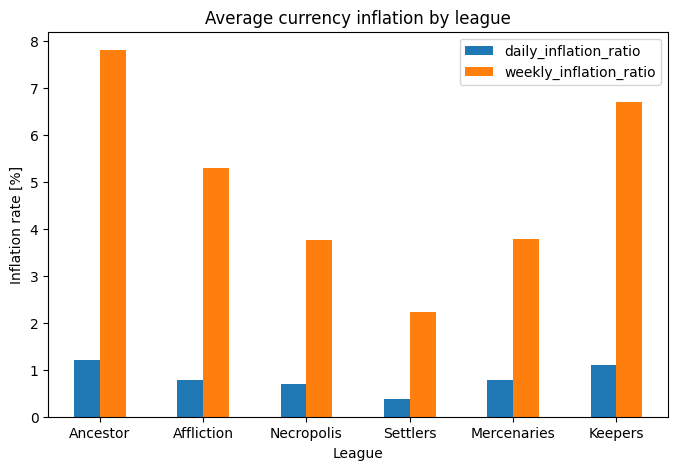

In [23]:
inflation_summary.plot(x="League",y=["daily_inflation_ratio", "weekly_inflation_ratio"], kind="bar",figsize=(8,5))

plt.ylabel("Inflation rate [%]")
plt.title("Average currency inflation by league")
plt.xticks(rotation=0)
plt.show()

**Conclusions:**

1. The comparison of average inflation rates shows substantial differences between leagues. The **Ancestor** league exhibits the highest inflation levels, with weekly inflation close to 8%. In real-world economic terms, inflation at this level would be considered very high, indicating a rapid decline in the purchasing power of the currency.

2. The **Keepers** and the **Affliction** leagues also show high inflation level, while **Necropolis** and **Mercenaries** leagues show lower inflation levels, with weekly values around 4%. This range is considered as moderate inflation and suggests a relatively stable currency market.

3. The **Settlers** league exhibits the lowest inflation among the analysed leagues, with weekly inflation close to 2.5%. In real-world economics, inflation around 2-2.5% is considered ideal, low, and stable, as it allows economic activity to grow, avoiding deflation at the same time. The **Settlers** league can therefore be considered the closest representation of an economically stable market. 

4. The daily and weekly measures follow the same relative ordering across leagues, suggesting that the observed differences reflect persistent economic characteristics of each league rather than short-term market fluctuations.
